# Практична робота №3 - Дослідження ефективності TF-IDF-зважених ембедингів для виявлення текстів, згенерованих великими мовними моделями (LLM).

*Мета роботи:* Засвоїти принципи побудови векторних представлень текстів на основі субслівних ембедингів (FastText), 
дослідити вплив TF-IDF-зважування на якість агрегації документних векторів, порівняти ефективність лінійних і нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарного виявлення штучно згенерованих текстів, а також проаналізувати геометричні властивості отриманих векторних просторів.

### 4.1. Етап 1. Завантаження та первинний аналіз даних
- Завантажити набір даних (датасет) і проаналізувати його структуру.
- Перевірити баланс класів і розподіл довжин текстів.
- Виявити можливі артефакти (дублікати, порожні рядки, надто короткі тексти).
- Побудувати гістограми розподілу кількості слів для кожного класу.

In [5]:
%pip install pandas matplotlib seaborn spacy gensim

  Using cached gensim-4.4.0.tar.gz (23.3 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Failed to build gensim
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  exit code: 1
  
  [806 lines of output]
  C:\Users\Vladimir\AppData\Local\Temp\pip-build-env-qko0_63a\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'test_suite'
    warnings.warn(msg)
  C:\Users\Vladimir\AppData\Local\Temp\pip-build-env-qko0_63a\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'tests_require'
    warnings.warn(msg)
  running bdist_wheel
  running build
  running build_py
  creating build\lib.win-amd64-cpython-314\gensim
  copying gensim\downloader.py -> build\lib.win-amd64-cpython-314\gensim
  copying gensim\interfaces.py -> build\lib.win-amd64-cpython-314\gensim
  copying gensim\matutils.py -> build\lib.win-amd64-cpython-314\gensim
  copying gensim\nosy.py -> build\lib.win-amd64-cpython-314\gensim
  copying gensim\utils.py -> build\lib.win-amd64-cpython-314\gensim
  copying gensim\__init__.py -> build\lib.win-amd64-c

Баланс класів:
label
human    1334
ai        666
Name: count, dtype: int64


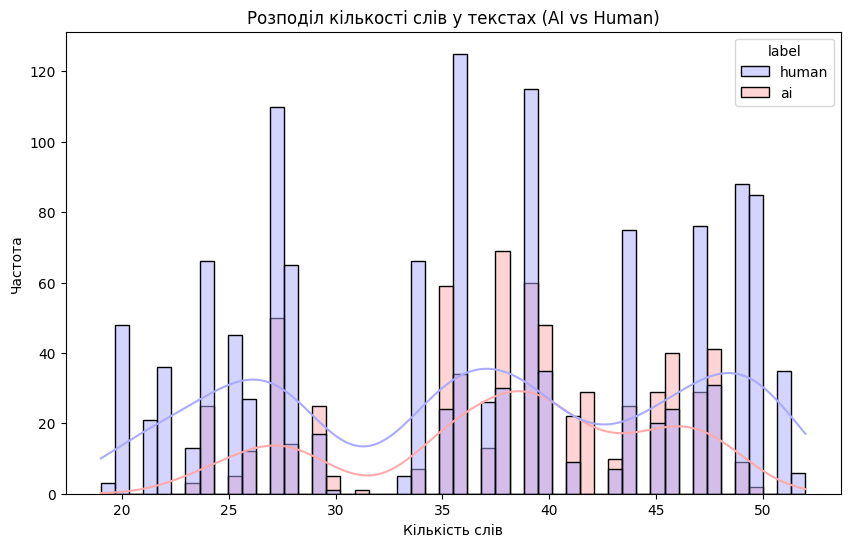

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Завантаження датасету
df = pd.read_csv('ai_vs_human_text_2026.csv')

# Перевірка балансу класів
print("Баланс класів:")
print(df['label'].value_counts())

# Аналіз відсутніх або порожніх текстів
df.dropna(subset=['text_content'], inplace=True)

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='word_count', hue='label', bins=50, kde=True, palette='bwr')
plt.title('Розподіл кількості слів у текстах (AI vs Human)')
plt.xlabel('Кількість слів')
plt.ylabel('Частота')
plt.show()

*Висновок:* Текстів, написаних людиною (1334), рівно вдвічі більше, ніж текстів, згенерованих ШІ (666) — співвідношення приблизно 2:1.
Такий дисбаланс означає, що базова метрика Accuracy (точність) може бути оманливою.

### Етап 2. Попередня обробка тексту (spaCy)
Реалізувати конвеєр (pipeline) обробки тексту з використанням бібліотеки spaCy:
- Лематизація — зведення слів до їхньої початкової форми.
- Видалення стоп-слів.
- Видалення небуквених символів.
- Перетворення тексту до нижнього регістру.
Примітка: Для прискорення обробки рекомендується використовувати nlp.pipe() із пакетною обробкою (batching).

In [7]:
import spacy

nlp = spacy.load("en_core_web_sm")

def preprocess_texts(texts): # Обробляє список текстів за допомогою nlp.pipe для оптимізації швидкості.
    processed_corpus = []
    # nlp.pipe застосовує batching для паралельної обробки
    for doc in nlp.pipe(texts, batch_size=100, n_process=-1):
        # Лематизація, зведення до нижнього регістру, відкидання стоп-слів та небуквених токенів
        tokens = [
            token.lemma_.lower() 
            for token in doc 
            if token.is_alpha and not token.is_stop
        ]
        processed_corpus.append(tokens)
    return processed_corpus

# Застосовує обробку до текстової колонки
df['processed_tokens'] = preprocess_texts(df['text_content'].tolist())
corpus = df['processed_tokens'].tolist()

print(f"Приклад обробленого тексту: {corpus[0]}")

Приклад обробленого тексту: ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


*Висновок*: З тексту повністю зникли неінформативні слова (прийменники, артиклі, допоміжні дієслова, займенники), які формували граматичну структуру, але не несли унікального змісту. Також видалено всі розділові знаки.
Лематизація: Слова були зведені до їхніх словникових (базових) форм. Наприклад,"editing" перетворилися на корінь "edit".
Перетворення тексту до нижнього регістру: Всі слова зведено до нижнього регістру.
Така попередня обробка дозволила очистити текст від шуму, залишивши лише слова, що передають основний зміст. Це важливо для наступних етапів, оскільки він суттєво зменшує розмірність словника моделі та дозволяє алгоритмам машинного навчання фокусуватися виключно на змісті та ключових маркерах ШІ або людини, не відволікаючись на особливості пунктуації чи словозміни.

### Етап 3. Навчання моделі FastText
За допомогою бібліотеки gensim навчити модель FastText на попередньо обробленому корпусі текстів.

In [8]:
from gensim.models import FastText

model = FastText(
    sentences=corpus,
    vector_size=100,  # Розмірність вектора
    window=5,         # Розмір вікна контексту
    min_count=2,      # Мінімальна кількість появ слова в корпусі
    sg=1,             # Архітектура Skip-gram
    workers=4,        # Кількість потоків
    seed=42           # Для відтворюваності експерименту
)

print(f"Розмір словника моделі: {len(model.wv.key_to_index)}")

ModuleNotFoundError: No module named 'gensim'